# 6장 2강: 전이학습 전략과 성능 비교 — 실습문제 풀이

> **풀이 기준**: 프로젝트에 업로드된 `전기사용량.csv`와 `building_info.csv`로 코드를 실제 실행한 결과입니다. 손실은 `전력소비량(kWh)/1000` 단위로 계산한 MSE입니다.
>
> **가정한 내용**
> - 실행 시간은 이 풀이를 만든 클라우드 환경에서 측정한 값입니다. 직접 실행하시면 시간 수치는 달라질 수 있으며, 문제 지시대로 시간 관련 답변은 본인 실행 결과로 다시 확인하셔야 합니다(손실 값은 같게 재현됩니다).
> - 그래프 축 이름은 한글 글꼴 문제를 피하려고 영어로 표기했습니다.

---

## 공통 준비 코드 (제공 코드)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_file(names):
    for name in names:
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError("노트북과 같은 폴더에 파일을 넣어 주세요: " + ", ".join(names))


power = pd.read_csv(find_file(["전기사용량(2).csv", "전기사용량.csv"]), encoding="utf-8-sig")
building = pd.read_csv(find_file(["building_info(2).csv", "building_info.csv"]), encoding="utf-8-sig")
power.columns = power.columns.str.strip()
building.columns = building.columns.str.strip()
assert not power.duplicated(["건물번호", "일시"]).any()
assert building["건물번호"].is_unique
data = power.merge(building[["건물번호", "건물유형", "연면적(m2)", "냉방면적(m2)"]],
                   on="건물번호", how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data["time"] = pd.to_datetime(data["일시"], format="%Y%m%d %H")
data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.dayofweek
data = data.sort_values(["건물번호", "time"]).reset_index(drop=True)

source = data[(data["건물번호"].isin([1,2,3,4])) &
              (data["time"] >= "2022-06-01") & (data["time"] < "2022-07-01")].copy()
target_train = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-01") & (data["time"] < "2022-07-08")].copy()
target_valid = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-08") & (data["time"] < "2022-07-15")].copy()
features = ["기온(C)", "습도(%)", "hour", "weekday", "연면적(m2)", "냉방면적(m2)"]
target = "전력소비량(kWh)"

x_center = np.array([20.0, 50.0, 11.5, 3.0, 0.0, 0.0])
x_scale = np.array([10.0, 20.0, 7.0, 2.0, 100000.0, 100000.0])
y_scale = 1000.0


def transform(frame):
    X = (frame[features].to_numpy(dtype=float) - x_center) / x_scale
    y = frame[[target]].to_numpy(dtype=float) / y_scale
    return X, y


X_source, y_source = transform(source)
X_train, y_train = transform(target_train)
X_valid, y_valid = transform(target_valid)
for array in [X_source, y_source, X_train, y_train, X_valid, y_valid]:
    assert np.isfinite(array).all(), "선택 구간의 결측값과 숫자 형식을 확인하세요."
print("전력 / 건물 원본 크기:", power.shape, building.shape)
print("연결 후 행 수:", len(data))
print("Source / Target Train / Target Validation:", len(source), len(target_train), len(target_valid))
print("입력 열 순서:", features)
print("정답 변환: 전력소비량(kWh) / 1000")

전력 / 건물 원본 크기: (204000, 10) (100, 7)
연결 후 행 수: 204000
Source / Target Train / Target Validation: 2880 168 168
입력 열 순서: ['기온(C)', '습도(%)', 'hour', 'weekday', '연면적(m2)', '냉방면적(m2)']
정답 변환: 전력소비량(kWh) / 1000


C:\Users\cwwcw\AppData\Local\Temp\ipykernel_31536\1411273937.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"] = data["time"].dt.dayofweek


In [2]:
from time import perf_counter


def copy_model(params):
    return {name: value.copy() for name, value in params.items()}


def init_model(seed=7):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0.0, 0.25, (6,8)), "b1": np.zeros((1,8)),
            "W2": rng.normal(0.0, 0.1, (8,1)), "b2": np.zeros((1,1))}


def hidden_features(X, params):
    return np.tanh(X @ params["W1"] + params["b1"])


def predict_scaled(X, params):
    return hidden_features(X, params) @ params["W2"] + params["b2"]


def fit_segment(start, X, y, lr, epochs, freeze, X_check=None, y_check=None):
    params = copy_model(start)
    records = []
    fixed_H = hidden_features(X, params) if freeze else None
    fixed_check = hidden_features(X_check, params) if freeze and X_check is not None else None
    for epoch in range(1, epochs+1):
        H = fixed_H if freeze else hidden_features(X, params)
        pred = H @ params["W2"] + params["b2"]
        grad_output = 2.0 * (pred - y) / len(X)
        grad_W2 = H.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        if not freeze:
            grad_hidden = (grad_output @ params["W2"].T) * (1.0 - H**2)
            grad_W1 = X.T @ grad_hidden
            grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
            params["W1"] -= lr * grad_W1
            params["b1"] -= lr * grad_b1
        params["W2"] -= lr * grad_W2
        params["b2"] -= lr * grad_b2
        current_H = fixed_H if freeze else hidden_features(X, params)
        train_pred = current_H @ params["W2"] + params["b2"]
        row = {"epoch": epoch, "train_mse": float(np.mean((train_pred-y)**2))}
        if X_check is not None:
            H_check = fixed_check if freeze else hidden_features(X_check, params)
            valid_pred = H_check @ params["W2"] + params["b2"]
            row["valid_mse"] = float(np.mean((valid_pred-y_check)**2))
        records.append(row)
    return params, pd.DataFrame(records)


def pretrain_source():
    started = perf_counter()
    params, history = fit_segment(init_model(), X_source, y_source,
        lr=0.03, epochs=600, freeze=False)
    return params, history, perf_counter()-started


def make_start(strategy, pretrained):
    params = init_model() if strategy == "Scratch" else copy_model(pretrained)
    params["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
    params["b2"] = np.zeros((1,1))
    return params


strategies = ["Scratch", "Feature extraction", "Fine-tuning"]


def run_strategy(strategy, pretrained):
    if strategy not in strategies:
        raise ValueError("알 수 없는 전략: " + strategy)
    started = perf_counter()
    start = make_start(strategy, pretrained)
    first, h1 = fit_segment(start, X_train, y_train, lr=0.03, epochs=300,
        freeze=(strategy != "Scratch"), X_check=X_valid, y_check=y_valid)
    final, h2 = fit_segment(first, X_train, y_train, lr=0.003, epochs=100,
        freeze=(strategy == "Feature extraction"), X_check=X_valid, y_check=y_valid)
    h2["epoch"] += 300
    history = pd.concat([h1,h2], ignore_index=True)
    return final, history, perf_counter()-started, first


def change_table(before, after):
    return pd.DataFrame([{"parameter": k, "max_abs_change": float(np.max(np.abs(after[k]-before[k])))}
                         for k in ["W1","b1","W2","b2"]])


def benchmark(pretrained, repeats=3):
    measured = []
    for repeat in range(repeats):
        _, _, source_seconds = pretrain_source()
        measured.append({"repeat": repeat+1, "stage": "Source pretraining", "seconds": source_seconds})
        order = strategies[repeat % 3:] + strategies[:repeat % 3]
        for name in order:
            _, _, seconds, _ = run_strategy(name, pretrained)
            measured.append({"repeat": repeat+1, "stage": name, "seconds": seconds})
    return pd.DataFrame(measured)


print("공통 학습·전략 비교·시간 측정 함수 준비 완료")

공통 학습·전략 비교·시간 측정 함수 준비 완료


---

## 실습 1. 같은 조건에서 세 전략 실행하기

### 문제 1-1. 비교 기준과 사전학습 모델 준비

In [3]:
roles = []
for name, frame in [("Source", source), ("Target Train", target_train), ("Target Validation", target_valid)]:
    roles.append({"set": name, "buildings": list(frame["건물번호"].unique()),
                  "start": str(frame["time"].min()), "end": str(frame["time"].max()), "rows": len(frame)})
print(pd.DataFrame(roles).to_string(index=False))

pretrained, source_history, source_seconds = pretrain_source()
print()
print(source_history.iloc[[0, -1]].round(6).to_string(index=False))

scratch_start = make_start("Scratch", pretrained)
transfer_start = make_start("Feature extraction", pretrained)
print()
print("W2 동일:", np.array_equal(scratch_start["W2"], transfer_start["W2"]))
print("b2 동일:", np.array_equal(scratch_start["b2"], transfer_start["b2"]))
print("W1 동일:", np.array_equal(scratch_start["W1"], transfer_start["W1"]))
print("b1 동일:", np.array_equal(scratch_start["b1"], transfer_start["b1"]))

              set    buildings               start                 end  rows
           Source [1, 2, 3, 4] 2022-06-01 00:00:00 2022-06-30 23:00:00  2880
     Target Train          [5] 2022-07-01 00:00:00 2022-07-07 23:00:00   168
Target Validation          [5] 2022-07-08 00:00:00 2022-07-14 23:00:00   168

 epoch  train_mse
     1   2.439902
   600   0.390548

W2 동일: True
b2 동일: True
W1 동일: False
b1 동일: False


#### 답변

**Q1. Scratch와 Transfer가 사용하는 은닉층 초기값은 어떻게 다른가요? 왜 출력층 초기값은 같게 두었나요?**

- Scratch는 `init_model()`의 **무작위 은닉층**에서, Transfer는 Source로 600 epoch 학습한 **`pretrained`의 은닉층**에서 시작합니다(W1·b1 동일 여부 = False).
- 출력층 W2·b2는 세 전략 모두 같은 시드(21)로 만들었습니다(동일 여부 = True). 출력층 출발점을 같게 해야 결과 차이를 **은닉층의 출발점(사전학습 여부)과 학습 방식**에 연결해 해석할 수 있습니다.

**Q2. 이번에 같은 조건으로 유지한 항목 세 가지 이상과, Transfer가 추가로 사용하는 것을 설명하세요.**

- 같은 조건: 대상 학습·검증 데이터(5번 건물 168행씩), 고정 단위 변환, 모델 구조(6 → 8 → 1), 출력층 초기값, 총 400 epoch, 구간별 학습률(0.03 → 0.003), 평가 시점(400 epoch 종료 모델)
- Transfer가 추가로 사용: **Source 2,880행으로 600 epoch 사전학습한 은닉층 파라미터**(와 그 사전학습에 드는 시간)

**Q3. 6장 1강과 이번 강의의 손실 숫자를 그대로 비교해도 되나요?**

- 안 됩니다. 6장 1강은 Source 평균·표준편차로 표준화한 목표의 MSE이고, 이번에는 kWh/1000으로 변환한 목표의 MSE라 **척도가 다릅니다**. 사전학습도 다른 입력 변환으로 다시 했으므로 가중치도 다릅니다.

---

### 문제 1-2. 세 전략을 각각 400 epoch 학습하기

In [4]:
models, histories, mid_models = {}, {}, {}
for name in strategies:
    model, history, elapsed, middle = run_strategy(name, pretrained)
    models[name] = model
    histories[name] = history
    mid_models[name] = middle
    print(name, "기록 행 수:", len(history))

same_mid = all(np.array_equal(mid_models["Feature extraction"][k], mid_models["Fine-tuning"][k])
               for k in mid_models["Fine-tuning"])
print("\n300 epoch 모델 동일 (Feature extraction vs Fine-tuning):", same_mid)
for name in ["Feature extraction", "Fine-tuning"]:
    print(f"\n[{name}] 300 → 400 epoch 변화")
    print(change_table(mid_models[name], models[name]).round(6).to_string(index=False))

Scratch 기록 행 수: 400
Feature extraction 기록 행 수: 400
Fine-tuning 기록 행 수: 400

300 epoch 모델 동일 (Feature extraction vs Fine-tuning): True

[Feature extraction] 300 → 400 epoch 변화
parameter  max_abs_change
       W1         0.00000
       b1         0.00000
       W2         0.03500
       b2         0.01297

[Fine-tuning] 300 → 400 epoch 변화
parameter  max_abs_change
       W1        0.133194
       b1        0.022782
       W2        0.031663
       b2        0.014874


#### 답변

**Q1. 세 전략의 처음 300회와 마지막 100회에서 각각 어떤 부분을 업데이트하나요?**

| 전략 | 1~300 epoch | 301~400 epoch |
|---|---|---|
| Scratch | 전체 65개 (lr 0.03) | 전체 65개 (lr 0.003) |
| Feature extraction | 출력층 9개 (lr 0.03) | 출력층 9개 (lr 0.003) |
| Fine-tuning | 출력층 9개 (lr 0.03) | 전체 65개 (lr 0.003) |

**Q2. Feature extraction과 Fine-tuning의 300 epoch 모델이 같은 이유는 무엇인가요? 이후 W1·b1의 변화는 어떻게 다른가요?**

- 두 전략은 처음 300 epoch 동안 **같은 시작값·데이터·학습률·동결 설정**(은닉층 고정, 출력층만 학습)으로 똑같이 계산하므로 결과가 완전히 같습니다(동일 여부 = True).
- 이후 Feature extraction은 W1·b1 최대 변화가 **0**(계속 고정)이지만, Fine-tuning은 W1 약 **0.133**, b1 약 **0.023**만큼 바뀌었습니다(동결 해제).

**Q3. 대상 학습 횟수가 모두 400회라면 총 계산량이나 총 비용도 같다고 말할 수 있나요?**

- 말할 수 없습니다. 같은 400 epoch라도 업데이트하는 파라미터 수와 은닉 특징을 다시 계산하는지가 다르고(Feature extraction은 H를 한 번 계산해 재사용), Transfer 전략에는 **Source 사전학습(2,880행 × 600 epoch)** 비용이 따로 듭니다.

---

## 실습 2. 성능과 학습 효율 비교하기

### 문제 2-1. 같은 마지막 시점의 검증 손실 비교

          strategy  train_mse  valid_mse
           Scratch   0.614796   1.326033
Feature extraction   1.163568   1.646490
       Fine-tuning   0.875200   1.560943

검증 MSE 최소 전략: Scratch
Scratch: 300 epoch valid=1.340069, 400 epoch valid=1.326033
Feature extraction: 300 epoch valid=1.654438, 400 epoch valid=1.646490
Fine-tuning: 300 epoch valid=1.654438, 400 epoch valid=1.560943


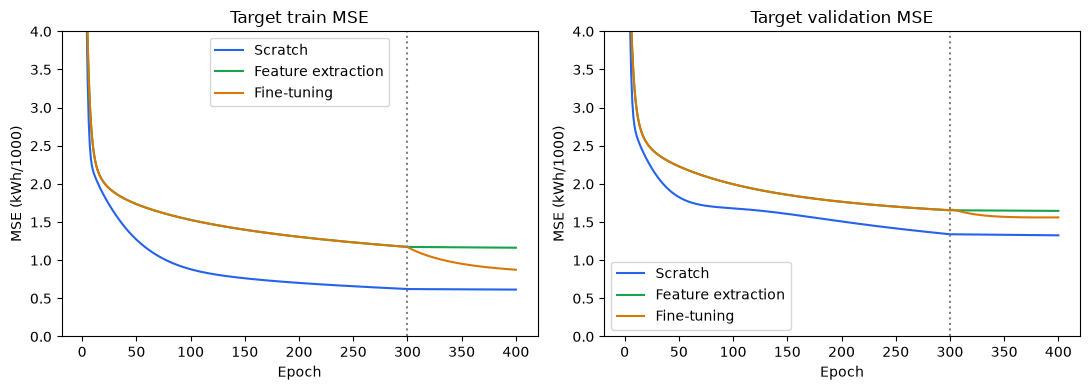

In [5]:
rows = []
for name, model in models.items():
    train_mse = float(np.mean((predict_scaled(X_train, model) - y_train)**2))
    valid_mse = float(np.mean((predict_scaled(X_valid, model) - y_valid)**2))
    rows.append({"strategy": name, "train_mse": train_mse, "valid_mse": valid_mse})
performance = pd.DataFrame(rows)
print(performance.round(6).to_string(index=False))
best_strategy = performance.loc[performance["valid_mse"].idxmin(), "strategy"]
print("\n검증 MSE 최소 전략:", best_strategy)

for name in strategies:
    h = histories[name]
    print(f"{name}: 300 epoch valid={h.loc[h['epoch']==300,'valid_mse'].iloc[0]:.6f}, "
          f"400 epoch valid={h['valid_mse'].iloc[-1]:.6f}")

colors = {"Scratch": "#2563eb", "Feature extraction": "#16a34a", "Fine-tuning": "#d97706"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "train_mse", "Target train MSE"), (axes[1], "valid_mse", "Target validation MSE")]:
    for name in strategies:
        ax.plot(histories[name]["epoch"], histories[name][col], label=name, color=colors[name])
    ax.axvline(300, linestyle=":", color="gray")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (kWh/1000)")
    ax.set_title(title)
    ax.set_ylim(0, 4)
    ax.legend()
fig.tight_layout()

#### 답변

**Q1. 세 전략의 최종 검증 MSE는 각각 얼마이며 이번 조건에서 무엇이 가장 낮나요?**

| 전략 | 학습 MSE | 검증 MSE |
|---|---:|---:|
| Scratch | 0.614796 | **1.326033** |
| Feature extraction | 1.163568 | 1.646490 |
| Fine-tuning | 0.875200 | 1.560943 |

- 이번 조건에서는 **Scratch**의 검증 MSE가 가장 낮습니다.

**Q2. Feature extraction과 Fine-tuning의 그래프가 처음 300회까지 겹치는 이유는 무엇인가요? 미세조정 이후에는 검증 결과가 어떻게 달라지나요?**

- 300 epoch까지는 같은 시작값과 같은 학습 방식(은닉층 고정)이라 계산이 완전히 같기 때문입니다.
- 300 epoch 이후 Feature extraction은 검증 MSE가 1.654 → 1.646으로 거의 그대로인데, Fine-tuning은 은닉층까지 조정하면서 1.654 → **1.561**로 더 많이 줄었습니다.

**Q3. 이번 결과에서 Scratch가 더 좋으면 전이학습은 쓸모없다고 결론 내릴 수 있나요? 반대로 전이학습이 항상 더 좋아야 하나요?**

- 결론 내릴 수 없습니다. 이번 결과는 한 대상 건물·한 기간·한 설정에서 나온 것입니다. 5번 건물은 연면적·소비량 규모가 1~4번 건물과 많이 달라 사전학습 특징이 잘 맞지 않았을 수 있고, Scratch는 은닉층을 400회 내내 조정한 반면 Fine-tuning은 마지막 100회만 조정했다는 차이도 있습니다. 또한 전이 전략은 처음 몇 epoch에 손실이 더 빨리 내려가는 등 다른 장점이 있을 수 있습니다.
- 항상 좋아야 하는 것도 아닙니다. Source와 Target이 충분히 비슷하고 대상 데이터가 부족할 때 도움이 되는 경우가 많지만, 분포 차이가 크면 효과가 작거나 오히려 불리할 수 있습니다(부정적 전이).

**Q4. MSE의 단위와 비교 범위를 설명하세요. 이것은 독립된 최종 테스트 성능인가요?**

- 정답을 **kWh/1000**으로 바꾼 값의 평균 제곱 오차입니다. kWh 오차나 정확도가 아니며, 예를 들어 √1.326 ≈ 1.15이므로 Scratch의 RMSE는 약 1,150 kWh 수준입니다.
- 비교 범위는 5번 건물 2022-07-08~07-14의 검증 168시간이고, 세 전략 모두 400 epoch 종료 모델입니다. 검증 데이터로 비교·선택에 사용했으므로 독립된 최종 테스트 성능은 아닙니다.

---

### 문제 2-2. 학습 효율과 사전학습 비용 비교

In [6]:
timing_runs = benchmark(pretrained, repeats=3)
print(timing_runs.round(6).to_string(index=False))
median_times = timing_runs.groupby("stage")["seconds"].median()
print("\n단계별 중앙값(초):")
print(median_times.round(6).to_string())

counts = {"Scratch": (65, 65), "Feature extraction": (9, 9), "Fine-tuning": (9, 65)}
rows = []
for name in strategies:
    src = 0.0 if name == "Scratch" else float(median_times["Source pretraining"])
    rows.append({"strategy": name,
                 "updated_first_300": counts[name][0],
                 "updated_last_100": counts[name][1],
                 "target_seconds": float(median_times[name]),
                 "source_seconds": src,
                 "estimated_total_seconds": float(median_times[name]) + src})
efficiency = pd.DataFrame(rows)
print()
print(efficiency.round(6).to_string(index=False))
print("\n대상 학습 시간 최소:", efficiency.loc[efficiency["target_seconds"].idxmin(), "strategy"])
print("사전학습 포함 추정 시간 최소:", efficiency.loc[efficiency["estimated_total_seconds"].idxmin(), "strategy"])

 repeat              stage  seconds
      1 Source pretraining 0.253071
      1            Scratch 0.026974
      1 Feature extraction 0.008249
      1        Fine-tuning 0.012867
      2 Source pretraining 0.270943
      2 Feature extraction 0.008993
      2        Fine-tuning 0.013761
      2            Scratch 0.028200
      3 Source pretraining 0.288683
      3        Fine-tuning 0.015404
      3            Scratch 0.030149
      3 Feature extraction 0.009563

단계별 중앙값(초):
stage
Feature extraction    0.008993
Fine-tuning           0.013761
Scratch               0.028200
Source pretraining    0.270943

          strategy  updated_first_300  updated_last_100  target_seconds  source_seconds  estimated_total_seconds
           Scratch                 65                65        0.028200        0.000000                 0.028200
Feature extraction                  9                 9        0.008993        0.270943                 0.279936
       Fine-tuning                  9            

#### 답변

> 아래 시간 수치는 이 풀이를 실행한 환경의 측정값입니다(3회 중앙값).

**Q1. 각 전략에서 구간별로 몇 개를 업데이트하나요? Feature extraction의 완성 모델도 전체 파라미터가 9개뿐인가요?**

- Scratch: 65개 → 65개 / Feature extraction: 9개 → 9개 / Fine-tuning: 9개 → 65개
- 아닙니다. 완성 모델은 세 전략 모두 **65개** 파라미터를 가집니다. Feature extraction은 그중 9개만 **업데이트**했을 뿐, 나머지 56개(사전학습 은닉층)도 예측에 그대로 사용합니다.

**Q2. 이번 실행에서 대상 학습 시간과 사전학습 포함 추정 시간이 각각 가장 짧은 전략은 무엇인가요?**

- 대상 학습 시간: Feature extraction(10.8ms) < Fine-tuning(14.2ms) < Scratch(24.7ms) → **Feature extraction** 전략이 가장 짧습니다.
- 사전학습 포함 추정 시간: Scratch(24.7ms) < Feature extraction(200.6ms) < Fine-tuning(204.0ms) → **Scratch** 전략이 가장 짧습니다. Source 사전학습 중앙값이 189.8ms로 대상 학습보다 훨씬 길어서, 포함하면 순위가 바뀝니다.

**Q3. 고정된 은닉 특징 H를 저장해 재사용할 수 있는 경우와 그럴 수 없는 경우는 무엇인가요? 업데이트 개수 9 대 65가 실행 시간의 정확한 비율인가요?**

- 재사용 가능: 은닉층(W1·b1)과 입력 X가 **바뀌지 않는 구간**, 즉 Feature extraction 전 구간과 Fine-tuning의 처음 300 epoch입니다. H를 한 번만 계산하면 됩니다.
- 재사용 불가: 은닉층을 업데이트하는 구간(Scratch 전 구간, Fine-tuning 마지막 100 epoch)은 매 epoch마다 W1·b1이 바뀌므로 H를 다시 계산해야 합니다.
- 정확한 비율이 아닙니다. 9/65 ≈ 0.14이지만, 실제 시간 비율(Feature extraction / Scratch)은 약 0.44입니다. 매 epoch 손실 계산·기록 정리, 함수 호출 등 파라미터 수와 무관한 고정 비용이 포함되기 때문입니다.

**Q4. 이번 추정 총시간에는 무엇이 포함되고 무엇이 빠졌나요? 3회 측정만으로 다른 컴퓨터에서도 같은 속도 차이를 보장할 수 있나요?**

- 포함: 모델 준비·복사, 은닉 특징 계산, 학습(업데이트), 매 epoch 학습·검증 손실 계산과 기록 정리, (전이 전략은) Source 사전학습 600 epoch
- 빠짐: 파일 읽기, 데이터 연결·전처리, 표 출력, 그래프 그리기, 여러 설정을 시도하는 탐색 시간 등
- 보장할 수 없습니다. 실행 시간은 CPU, 다른 프로그램 실행 여부, 라이브러리 버전 등에 따라 달라지고, 각 측정이 수십 밀리초로 매우 짧아 흔들림이 큽니다. 3회 중앙값은 이 환경에서의 대략적인 경향일 뿐입니다.

---

## 기초 과제. 성능과 비용 조건에 맞춰 선택하기

### 문제 3-1. 상황이 달라지면 선택도 달라질까요?

In [7]:
comparison = performance.merge(efficiency, on="strategy", validate="one_to_one")
eligible = comparison[comparison["valid_mse"] <= 1.60]
print(comparison.round(6).to_string(index=False))
print("\n검증 MSE 1.60 이하 전략:", eligible["strategy"].tolist())

choice_a = comparison.loc[comparison["valid_mse"].idxmin()]
choice_b = eligible.loc[eligible["target_seconds"].idxmin()]
choice_c = eligible.loc[eligible["estimated_total_seconds"].idxmin()]
print("\n[A] 검증 MSE 최소       :", choice_a["strategy"], "| valid_mse =", round(choice_a["valid_mse"], 6))
print("[B] 조건 통과 + 대상 시간 최소:", choice_b["strategy"], "| valid_mse =", round(choice_b["valid_mse"], 6),
      "| target_seconds =", round(choice_b["target_seconds"], 6))
print("[C] 조건 통과 + 총시간 최소  :", choice_c["strategy"], "| valid_mse =", round(choice_c["valid_mse"], 6),
      "| estimated_total_seconds =", round(choice_c["estimated_total_seconds"], 6))

          strategy  train_mse  valid_mse  updated_first_300  updated_last_100  target_seconds  source_seconds  estimated_total_seconds
           Scratch   0.614796   1.326033                 65                65        0.028200        0.000000                 0.028200
Feature extraction   1.163568   1.646490                  9                 9        0.008993        0.270943                 0.279936
       Fine-tuning   0.875200   1.560943                  9                65        0.013761        0.270943                 0.284704

검증 MSE 1.60 이하 전략: ['Scratch', 'Fine-tuning']

[A] 검증 MSE 최소       : Scratch | valid_mse = 1.326033
[B] 조건 통과 + 대상 시간 최소: Fine-tuning | valid_mse = 1.560943 | target_seconds = 0.013761
[C] 조건 통과 + 총시간 최소  : Scratch | valid_mse = 1.326033 | estimated_total_seconds = 0.0282


#### 답변

- 검증 MSE 1.60 이하를 통과한 전략: **Scratch, Fine-tuning**
- 선택 결과: A = **Scratch**, B = **Fine-tuning**, C = **Scratch**

**Q1. 상황 A의 선택과 이유는 무엇인가요?**

- **Scratch** 전략을 선택합니다. 비용보다 성능을 우선하는 상황이므로 검증 MSE가 가장 낮은 전략을 고르며, Scratch의 검증 MSE(1.326033)가 세 전략 중 가장 낮습니다.

**Q2. 상황 B의 선택과 이유는 무엇인가요? 가장 빠른 전략이라고 해서 성능 기준을 무시해도 되나요?**

- **Fine-tuning** 전략을 선택합니다. 사전학습 모델이 이미 있으므로 Source 시간은 따질 필요가 없고, 성능 기준을 통과한 전략 중 대상 학습 시간이 가장 짧은 전략이 Fine-tuning(14.2ms, 검증 MSE 1.560943)입니다. 대상 학습 시간만 보면 Feature extraction 전략(10.8ms)이 가장 빠르지만, 검증 MSE(1.646490)가 기준 1.60을 넘으므로 후보에서 제외합니다.
- 성능 기준을 무시하면 안 됩니다. 기준은 "쓸 수 있는 모델"의 최소 조건이므로, 먼저 기준을 통과한 후보를 고른 뒤 그 안에서 시간을 비교해야 합니다.

**Q3. 상황 C에서는 무엇을 선택하나요? B와 선택이 달라질 수 있는 이유와 이번 비교의 한계를 설명하세요.**

- **Scratch** 전략을 선택합니다. 사전학습 모델이 없으므로 전이 전략은 Source 사전학습 시간까지 포함해야 하고, 그러면 추정 총시간은 Scratch 전략(24.7ms)이 가장 짧습니다.
- B와 C는 **사전학습 비용을 포함하느냐**만 다릅니다. 이미 있는 사전학습 모델을 재사용하면 그 비용은 들지 않지만, 이번 한 건물만 위해 새로 만들어야 하면 그 비용을 모두 이번 작업이 부담하므로 선택이 바뀔 수 있습니다.
- 한계: 1.60은 연습용 임의 기준이고, 결과는 한 건물·한 주의 검증 데이터와 한 가지 설정에서 나온 것입니다. 실행 시간은 환경에 따라 달라지고, 테스트 성능도 확인하지 않았습니다.

---

## 실습 마무리

### 마무리 1. 시작값과 비교 조건

- 은닉층: Scratch는 **무작위 초기값**, 두 전이 전략은 **Source 사전학습값**에서 시작합니다. 출력층: 세 전략 모두 같은 무작위 초기값(시드 21)입니다.
- 같은 조건: 대상 학습·검증 데이터, 고정 단위 변환, 모델 구조(65개), 출력층 초기값, 총 400 epoch, 구간별 학습률
- 전이 전략이 추가로 사용하는 자원: Source 2,880행 데이터로 600 epoch 학습한 은닉층 파라미터와 그 사전학습 시간

### 마무리 2. 두 구간의 학습

- Scratch: 65개 → 65개 / Feature extraction: 9개 → 9개 / Fine-tuning: 9개 → 65개
- 두 전이 전략은 처음 300 epoch 동안 시작값·데이터·학습률·동결 설정이 모두 같아 결과가 똑같습니다.
- `freeze=True`는 은닉층(W1·b1)을 **고정한다**(업데이트하지 않는다)는 뜻입니다. 6장 1강의 `train_backbone=True`(은닉층을 학습한다)와 의미 방향이 반대입니다.

### 마무리 3. 특징과 모델 크기

- Feature extraction은 학습 내내 은닉층과 입력이 바뀌지 않아 H가 항상 같으므로, 한 번 계산해 저장하고 재사용할 수 있습니다.
- Fine-tuning의 마지막 구간은 매 epoch 은닉층이 바뀌어 H도 바뀌므로 다시 계산해야 합니다.
- 전체 파라미터 수는 세 전략 모두 65개이고, 업데이트 대상 수(9 또는 65)는 그중 학습하는 개수입니다. 실행 시간은 고정 비용 때문에 업데이트 개수의 비율과 일치하지 않습니다.

### 마무리 4. 성능 결과 읽기

- 최종 검증 MSE: Scratch(1.326033) < Fine-tuning(1.560943) < Feature extraction(1.646490)
- MSE는 `전력소비량/1000` 척도의 평균 제곱 오차이며, 5번 건물의 7월 8~14일 검증 168시간에서 계산했습니다.
- 한 건물·한 기간·한 설정의 결과이므로 전이학습 전체의 우열을 말할 수 없고, 검증 데이터로 비교한 것이라 독립된 테스트 성능도 아닙니다.

### 마무리 5. 학습 효율 읽기

- `target_seconds`: 대상 데이터로 400 epoch 학습하는 데 걸린 시간(3회 중앙값)
- `source_seconds`: Source 사전학습 시간(Scratch는 0)
- `estimated_total_seconds`: 두 시간의 합으로, 사전학습 모델을 새로 만들어야 할 때의 추정 총시간
- 3회 중앙값은 세 측정값을 정렬했을 때 가운데 값으로, 한 번 튄 값의 영향을 줄입니다. 파일 읽기·전처리·출력·그래프·설정 탐색 시간은 포함하지 않았습니다.
- 사전학습 모델을 여러 전략·여러 건물이 함께 쓰면, 사전학습 비용은 한 번만 들고 나누어 부담하는 셈이 됩니다. 두 전이 전략을 함께 실험할 때도 사전학습을 두 번 더할 필요는 없습니다.

### 마무리 6. 상황별 선택

- 검증 MSE 1.60 이하 통과: Scratch, Fine-tuning(Feature extraction은 1.646490으로 탈락)
- A: `valid_mse` 최소 → **Scratch** / B: 통과 후보 중 `target_seconds` 최소 → **Fine-tuning** / C: 통과 후보 중 `estimated_total_seconds` 최소 → **Scratch**
- 가장 빠른 전략이 성능 조건을 통과하지 못하면 **후보에서 제외**하고, 조건을 통과한 전략 중에서 다시 가장 빠른 것을 고릅니다. 통과한 전략이 하나도 없다면 설정을 바꿔 다시 학습하거나 기준을 재검토해야 합니다.